# Stain variation and near-duplicates

Two questions, one set of features (`python scripts/image_features.py`):

**1. How much does staining vary, and does it matter?**
Every tile carries the colour signature of the slide it was cut from - the H&E batch, the
scanner, the section thickness. Patches from one slide share that signature, so the mean colour
of a tile is the closest thing we have to a **slide id**, which Kaggle does not publish. If
staining correlates with the label, colour becomes a shortcut the model will happily learn and
which will not transfer. This is the main domain shift in the problem and the argument for stain
augmentation.

**2. Are there near-duplicate tiles, and do they straddle folds?**
Tiles sampled from overlapping positions on the same slide look nearly identical. If one lands in
train and its twin in validation, the validation score is inflated. Exact duplicates are already
ruled out (`scripts/make_splits.py` hashes every image: zero found). This notebook looks for
*near* duplicates with a 56-bit dHash and feeds the groups back into the fold assignment.

In [3]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans

DATA  = Path(os.environ.get("HCD_DATA", Path.cwd().parent / "data"))
MM, CACHE = DATA / "memmap", DATA / "cache"

tr = pd.read_parquet(CACHE / "features_train.parquet")
te = pd.read_parquet(CACHE / "features_test.parquet")
tr_img = np.load(MM / "train_images.npy", mmap_mode="r")   # row i == features row i

COLS = ["r_mean", "g_mean", "b_mean"]
print(len(tr), "train /", len(te), "test")
tr[COLS + ["std"]].describe().round(1)

220025 train / 57458 test


,r_mean,g_mean,b_mean,std
count,220025.0,220025.0,220025.0,220025.0
mean,179.1,139.3,177.6,51.6
std,37.0,48.7,33.5,13.2
min,0.0,0.0,0.0,0.0
25%,151.1,101.1,154.8,45.6
50%,178.4,130.5,177.3,54.1
75%,210.5,177.1,202.3,60.6
max,255.0,255.0,255.0,110.5


## 1. The colour space the tiles live in

Each point is one tile's mean colour. If staining were uniform this would be a single blob;
the structure you see is slide-to-slide and scanner-to-scanner variation.

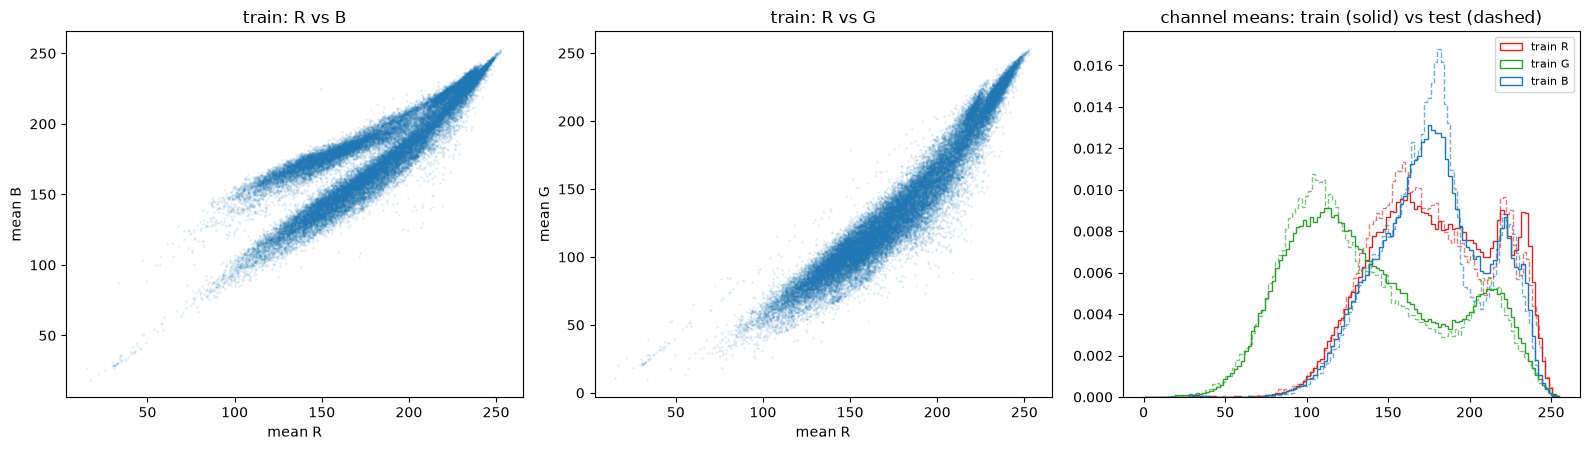

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
s = tr.sample(40_000, random_state=0)
axes[0].scatter(s["r_mean"], s["b_mean"], s=1, alpha=.08, c="tab:blue")
axes[0].set_xlabel("mean R"); axes[0].set_ylabel("mean B"); axes[0].set_title("train: R vs B")
axes[1].scatter(s["r_mean"], s["g_mean"], s=1, alpha=.08, c="tab:blue")
axes[1].set_xlabel("mean R"); axes[1].set_ylabel("mean G"); axes[1].set_title("train: R vs G")
for c, col in zip(["tab:red", "tab:green", "tab:blue"], COLS):
    axes[2].hist(tr[col], bins=120, histtype="step", density=True, color=c, label=f"train {col[0].upper()}")
    axes[2].hist(te[col], bins=120, histtype="step", density=True, color=c, ls="--", alpha=.6)
axes[2].legend(fontsize=8); axes[2].set_title("channel means: train (solid) vs test (dashed)")
plt.tight_layout(); plt.show()

## 2. Stain clusters as a stand-in for slide id

k-means on the mean RGB. Each cluster is a group of tiles that were probably stained and scanned
together. Three things to read off the table:

* **`test_pct` vs `train_pct`** - if every cluster appears in both splits at a similar rate, train
  and test draw on the same slide pool. A cluster present in one and absent from the other would
  mean the splits are slide-disjoint, which would change how much to trust random-split validation.
* **`pos_rate`** - how strongly colour predicts the label. Spread here is a confounder warning.
* **`centre_RGB`** - what the cluster actually looks like.

In [5]:
K = 20
km = MiniBatchKMeans(n_clusters=K, random_state=0, n_init=10, batch_size=4096).fit(tr[COLS].to_numpy())
tr["cl"] = km.predict(tr[COLS].to_numpy())
te["cl"] = km.predict(te[COLS].to_numpy())

rep = pd.DataFrame({
    "train_n":   tr.groupby("cl").size(),
    "train_pct": 100 * tr.groupby("cl").size() / len(tr),
    "test_pct":  100 * te.groupby("cl").size() / len(te),
    "pos_rate":  tr.groupby("cl")["label"].mean(),
})
rep["centre_RGB"] = [np.round(km.cluster_centers_[i]).astype(int).tolist() for i in rep.index]
rep.round(3).sort_values("train_pct", ascending=False)

,train_n,train_pct,test_pct,pos_rate,centre_RGB
cl,,,,,
11,21054,9.569,10.039,0.131,"[225, 208, 220]"
4,17426,7.920,6.706,0.079,"[237, 228, 233]"
0,15220,6.917,6.088,0.315,"[216, 188, 207]"
13,14320,6.508,6.083,0.595,"[195, 155, 178]"
2,14300,6.499,6.955,0.512,"[183, 140, 167]"
8,13995,6.361,5.531,0.517,"[205, 170, 193]"
12,13626,6.193,6.175,0.467,"[172, 126, 156]"
5,13372,6.077,8.918,0.688,"[157, 101, 179]"
6,13047,5.930,7.256,0.544,"[141, 86, 170]"


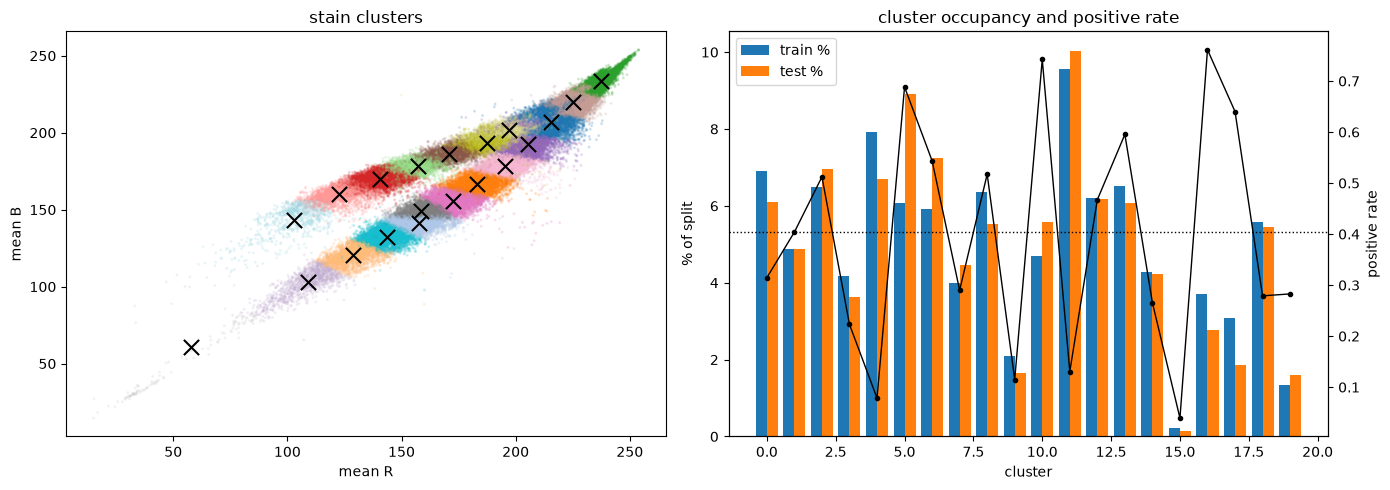

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
s = tr.sample(60_000, random_state=0)
ax[0].scatter(s["r_mean"], s["b_mean"], s=1.5, alpha=.15, c=s["cl"], cmap="tab20")
ax[0].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 2], s=120, c="k", marker="x")
ax[0].set_xlabel("mean R"); ax[0].set_ylabel("mean B"); ax[0].set_title("stain clusters")

w = 0.4
ax[1].bar(rep.index - w/2, rep["train_pct"], w, label="train %")
ax[1].bar(rep.index + w/2, rep["test_pct"],  w, label="test %")
ax2 = ax[1].twinx()
ax2.plot(rep.index, rep["pos_rate"], "k.-", lw=1, label="positive rate")
ax2.axhline(tr["label"].mean(), color="k", ls=":", lw=1)
ax2.set_ylabel("positive rate")
ax[1].set_xlabel("cluster"); ax[1].set_ylabel("% of split"); ax[1].legend(loc="upper left")
ax[1].set_title("cluster occupancy and positive rate")
plt.tight_layout(); plt.show()

### What the clusters look like

One row per cluster, eight random tiles from it. If the clustering is picking up staining rather
than content, each row should look colour-coherent while showing varied tissue.

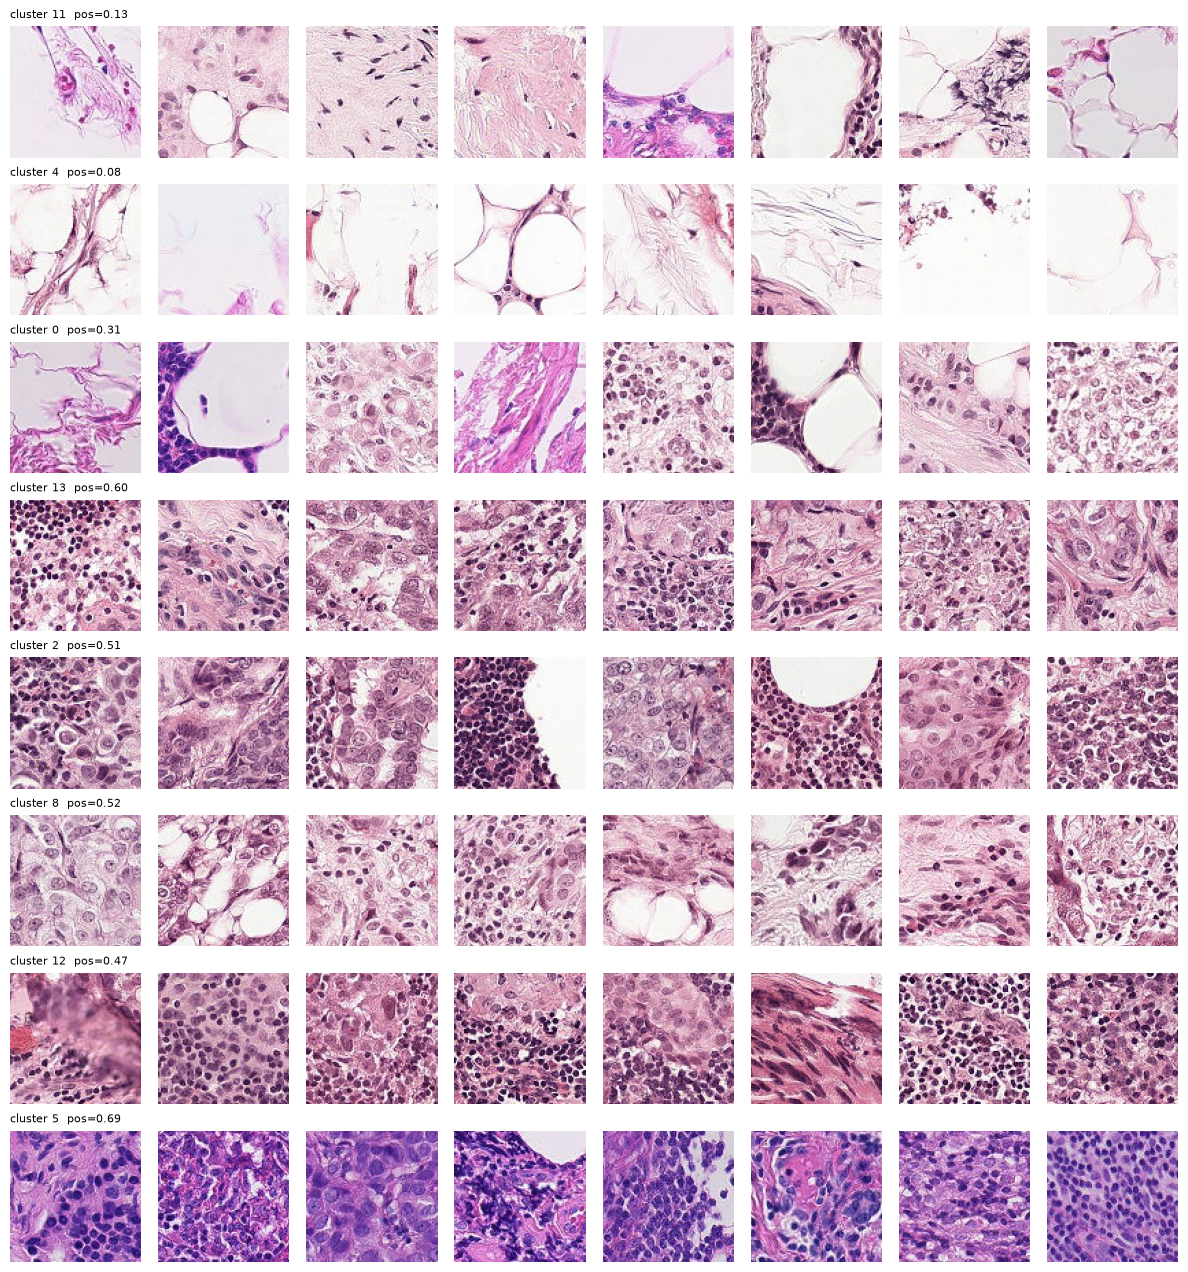

In [7]:
show = rep.sort_values("train_pct", ascending=False).index[:8]
fig, axes = plt.subplots(len(show), 8, figsize=(8 * 1.5, len(show) * 1.6))
axes = np.atleast_2d(axes)
for r, cl in enumerate(show):
    rows = tr.index[tr["cl"] == cl]
    for c, i in enumerate(np.random.default_rng(0).choice(rows, 8, replace=False)):
        axes[r, c].imshow(tr_img[i]); axes[r, c].axis("off")
    axes[r, 0].set_ylabel(f"c{cl}")
    axes[r, 0].set_title(f"cluster {cl}  pos={rep.loc[cl, 'pos_rate']:.2f}", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

## 3. Near-duplicates

A 56-bit dHash of the 8x8 block-mean grayscale. Identical hash = visually near-identical tile.
Flat/blank tiles all hash the same way - that is a property of the hash, not evidence that they
are duplicates of each other, so they are excluded from grouping below.

In [8]:
flat = tr["std"] < 10
for name, d in (("train", tr), ("test", te)):
    vc = d["dhash"].value_counts()
    multi = vc[vc > 1]
    print(f"{name}: {d['dhash'].nunique()} distinct hashes | {len(multi)} multi-member groups | "
          f"{int(multi.sum() - len(multi))} redundant images "
          f"({100 * (multi.sum() - len(multi)) / len(d):.2f}%) | largest group {int(vc.max())}")

nf = tr[~flat]
vcn = nf["dhash"].value_counts()
print("\ngroup sizes among non-flat train tiles:")
print(vcn.value_counts().sort_index().head(8).to_string())

shared = set(nf["dhash"]) & set(te.loc[te["std"] >= 10, "dhash"])
print(f"\nnon-flat dHashes shared between train and test: {len(shared)}")

train: 219952 distinct hashes | 6 multi-member groups | 73 redundant images (0.03%) | largest group 45
test: 57440 distinct hashes | 3 multi-member groups | 18 redundant images (0.03%) | largest group 11

group sizes among non-flat train tiles:
count
1     218401
2          2
3          1
22         1
33         1

non-flat dHashes shared between train and test: 5


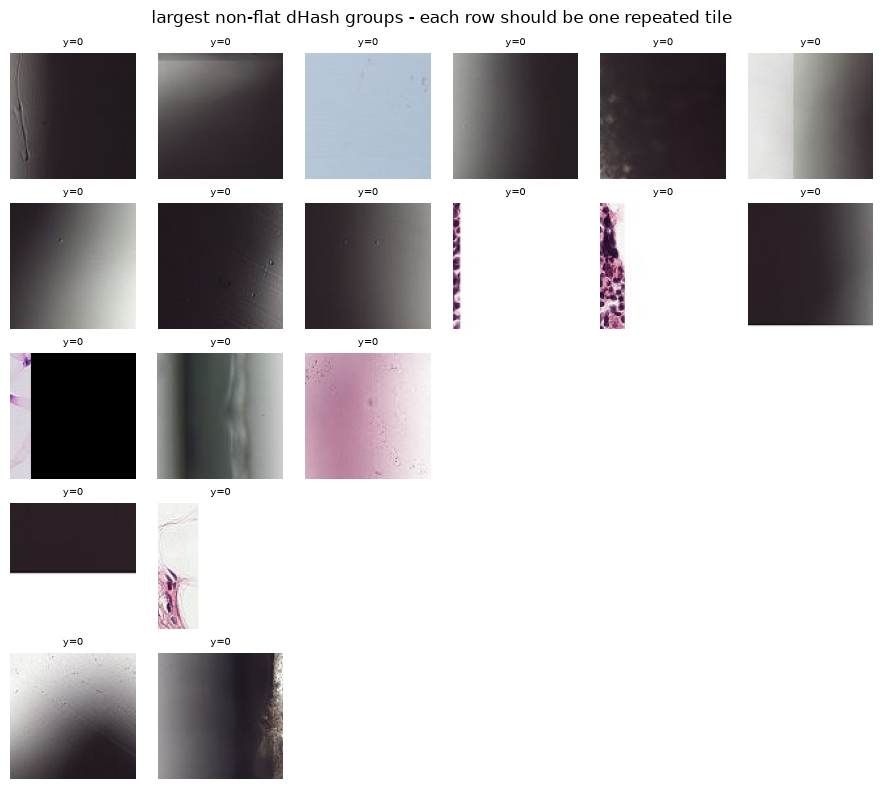

In [9]:
# look at a few of the largest non-flat groups: are they really near-identical?
groups = vcn[vcn > 1].index[:6]
fig, axes = plt.subplots(max(len(groups), 2), 6, figsize=(6 * 1.5, max(len(groups), 2) * 1.6))
axes = np.atleast_2d(axes)
for r, h in enumerate(groups):
    rows = nf.index[nf["dhash"] == h][:6]
    for c in range(6):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(rows):
            ax.imshow(tr_img[rows[c]])
            ax.set_title(f"y={int(tr.loc[rows[c], 'label'])}", fontsize=7)
fig.suptitle("largest non-flat dHash groups - each row should be one repeated tile")
plt.tight_layout(); plt.show()

## 4. How much of the label does colour alone explain?

The positive rate ranged from about 0.04 to 0.76 across stain clusters, so mean colour clearly
carries label information. This puts a number on it: gradient boosting on nothing but the eight
colour summaries, trained on folds 1-4 and scored on fold 0.

Two things are mixed together in that number and cannot be fully separated without slide ids:

* **Biology.** Tumour tissue is nuclei-dense, takes up more haematoxylin, and genuinely looks
  darker and more purple. That signal is real and will transfer.
* **Slide identity.** Slides with large metastases contain mostly positive tiles. A model that
  learns "this slide's colour" gets those tiles right for the wrong reason.

Either way it sets the floor your CNN has to clear, and it is much higher than people assume.

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

folds = pd.read_csv(Path.cwd().parent / "splits" / "folds.csv")
assert (folds["id"].to_numpy() == tr["id"].to_numpy()).all(), "folds.csv and features are out of order"

FEATS = ["r_mean", "g_mean", "b_mean", "r_std", "g_std", "b_std", "mean", "std"]
X, y = tr[FEATS].to_numpy(), tr["label"].to_numpy()
val = folds["fold"].to_numpy() == 0

for name, cols in [("all 8 colour features", slice(None)), ("mean RGB only", slice(0, 3))]:
    m = HistGradientBoostingClassifier(max_iter=200, random_state=0).fit(X[~val][:, cols], y[~val])
    auc = roc_auc_score(y[val], m.predict_proba(X[val][:, cols])[:, 1])
    print(f"{name:24s} fold-0 AUC = {auc:.4f}")
print("\nchance = 0.5; a good CNN on this dataset reaches ~0.98-0.99")

all 8 colour features    fold-0 AUC = 0.9151
mean RGB only            fold-0 AUC = 0.8709

chance = 0.5; a good CNN on this dataset reaches ~0.98-0.99
